# Chapter 3b: Time Series Features

> **Data** clinic_admissions_daily.csv · **Time** 50 min · **Needs first** C3

## What you will be able to do

1. Build lag features with .shift() and choose lags from the autocorrelation
2. Build rolling and expanding statistics that exclude the current row
3. Encode a cyclical feature with sine and cosine, and say why the raw integer fails
4. Split a time series chronologically with TimeSeriesSplit
5. Identify a feature that leaks the future, given a feature list

## The one idea to hold on to

Every time series feature is a promise about what you knew, and when. Break that promise and the model scores beautifully and forecasts nothing.

Welcome to Time Series Feature Engineering! Time series data has a **temporal structure** that requires special handling. Unlike regular tabular data, the order of observations matters - what happened yesterday affects today.

---

### Why Time Series Feature Engineering?

| Application | Example Features |
| :--- | :--- |
| **Stock Prediction** | Previous day prices, 7-day moving average |
| **Admissions Forecasting** | Last week admissions, same day last year |
| **Energy Demand** | Hour of day, day of week patterns |
| **Sensor Data** | Rolling mean, trend indicators |

> **Important:** Never use future data to predict the past - this creates **data leakage**!

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Understanding Time Series Data

Time series data is a sequence of observations recorded at successive points in time. Key characteristics:

| Characteristic | Description |
| :--- | :--- |
| **Temporal Order** | Observations are ordered by time - order matters! |
| **Autocorrelation** | Current values are correlated with past values |
| **Trend** | Long-term increase or decrease |
| **Seasonality** | Regular patterns that repeat (daily, weekly, yearly) |

### The Dataset

`clinic_admissions_daily.csv` holds three years of daily admissions at Northbridge Community Clinic, plus staff on duty and mean waiting time.

It has a real weekly step rather than a smooth wave (weekends run about 24% below weekdays), a mild upward trend and a yearly cycle. `data/generate_datasets.py` asserts on every build that lag-7 correlates with today more strongly than lag-1 does, and that an unshifted rolling mean scores R2 0.614 against the honest 0.390. Those are the two numbers this chapter turns on.

In [2]:
# Northbridge Community Clinic: daily admissions, three years.
df = pd.read_csv('../../00-data/clinic_admissions_daily.csv', parse_dates=['date'])

# Set date as index for time series operations
df = df.sort_values('date').set_index('date')

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")
df.head(10)

Dataset shape: (1096, 3)
Date range: 2023-01-01 to 2025-12-31


,admissions,staff_on_duty,mean_wait_minutes
date,,,
2023-01-01,57,31,14.4
2023-01-02,64,30,26.8
2023-01-03,67,31,25.9
2023-01-04,58,25,22.2
2023-01-05,56,29,12.5
2023-01-06,68,29,22.1
2023-01-07,54,29,18.8
2023-01-08,45,26,10.9
2023-01-09,86,35,33.6


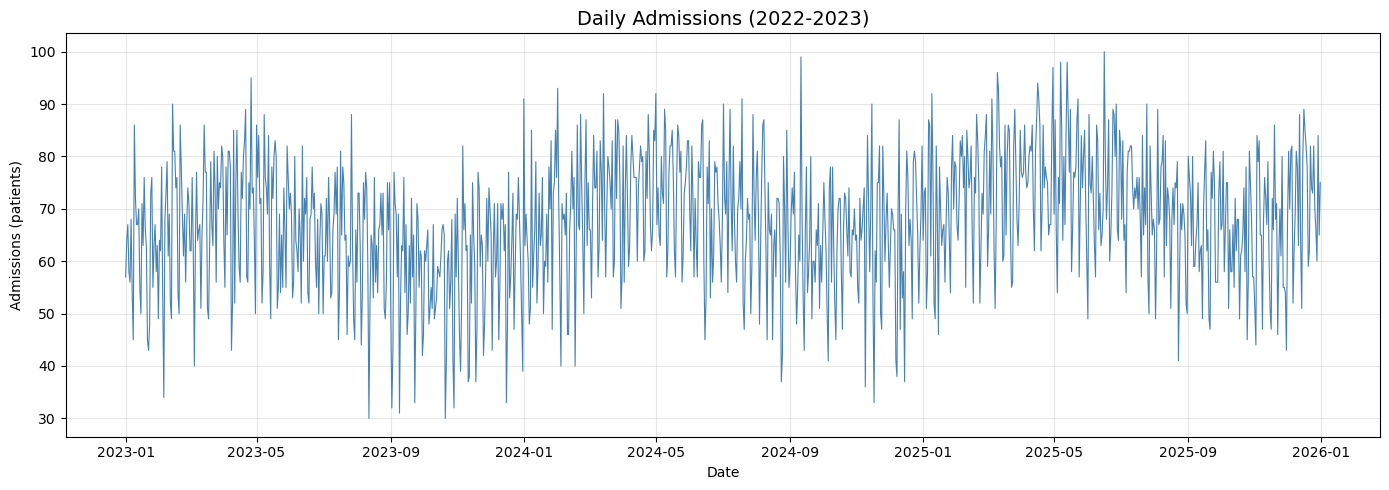

In [3]:
# Visualize the time series
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df['admissions'], color='steelblue', linewidth=0.8)
ax.set_title('Daily Admissions (2022-2023)', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Admissions (patients)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 2. Lag Features (Shift Operations)

**Lag features** use past values to predict future values. They are the foundation of time series modeling.

```
Day 1: 100  →  Lag-1: NaN,    Lag-2: NaN
Day 2: 120  →  Lag-1: 100,    Lag-2: NaN
Day 3: 115  →  Lag-1: 120,    Lag-2: 100
Day 4: 130  →  Lag-1: 115,    Lag-2: 120
```

### Creating Lag Features with `.shift()`

In [4]:
# Create lag features
df_features = df.copy()

# Lag 1: Previous day's admissions
df_features['admissions_lag1'] = df_features['admissions'].shift(1)

# Lag 7: Same day last week
df_features['admissions_lag7'] = df_features['admissions'].shift(7)

# Lag 14: Two weeks ago
df_features['admissions_lag14'] = df_features['admissions'].shift(14)

# Lag 365: Same day last year (useful for yearly patterns)
df_features['admissions_lag365'] = df_features['admissions'].shift(365)

print("Lag features created!")
df_features[['admissions', 'admissions_lag1', 'admissions_lag7', 'admissions_lag14']].head(15)

Lag features created!


,admissions,admissions_lag1,admissions_lag7,admissions_lag14
date,,,,
2023-01-01,57,NaN,NaN,NaN
2023-01-02,64,57.0,NaN,NaN
2023-01-03,67,64.0,NaN,NaN
2023-01-04,58,67.0,NaN,NaN
2023-01-05,56,58.0,NaN,NaN
2023-01-06,68,56.0,NaN,NaN
2023-01-07,54,68.0,NaN,NaN
2023-01-08,45,54.0,57.0,NaN
2023-01-09,86,45.0,64.0,NaN


In [5]:
# Create multiple lags efficiently using a loop
lags = [1, 2, 3, 7, 14, 21, 28]

for lag in lags:
    df_features[f'admissions_lag{lag}'] = df_features['admissions'].shift(lag)

print(f"Created {len(lags)} lag features!")
print("Lag columns:", [col for col in df_features.columns if 'lag' in col])

Created 7 lag features!
Lag columns: ['admissions_lag1', 'admissions_lag7', 'admissions_lag14', 'admissions_lag365', 'admissions_lag2', 'admissions_lag3', 'admissions_lag21', 'admissions_lag28']


### Visualizing Lag Correlation

Autocorrelation shows how well past values predict current values.

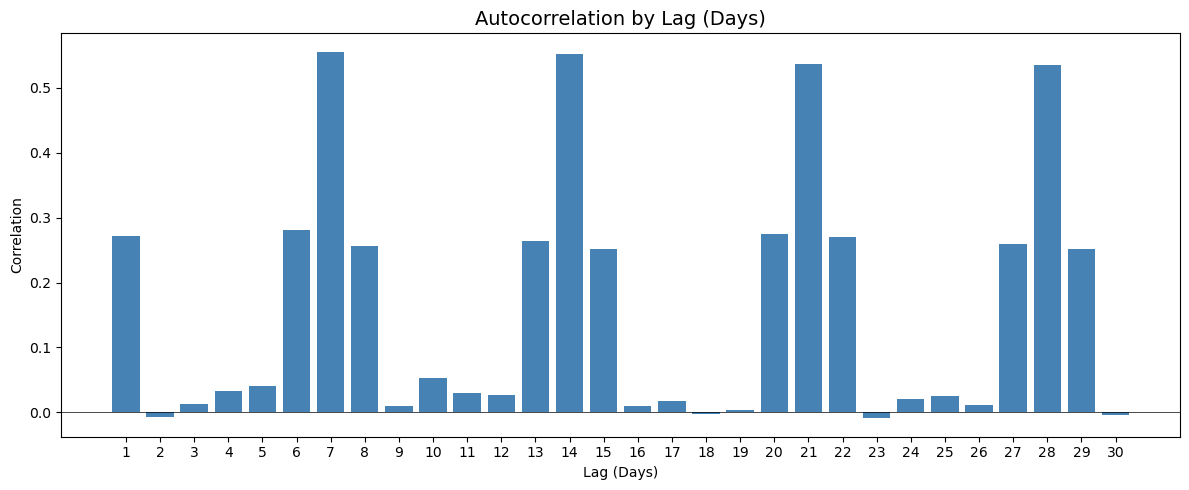


Top 5 most correlated lags:
    lag  correlation
6     7     0.555716
13   14     0.551472
20   21     0.536973
27   28     0.535897
5     6     0.281690


In [6]:
# Calculate autocorrelation for different lags
autocorr = []
for lag in range(1, 31):
    corr = df_features['admissions'].autocorr(lag=lag)
    autocorr.append({'lag': lag, 'correlation': corr})

autocorr_df = pd.DataFrame(autocorr)

# Plot autocorrelation
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(autocorr_df['lag'], autocorr_df['correlation'], color='steelblue')
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax.set_title('Autocorrelation by Lag (Days)', fontsize=14)
ax.set_xlabel('Lag (Days)')
ax.set_ylabel('Correlation')
ax.set_xticks(range(1, 31))
plt.tight_layout()
plt.show()

print("\nTop 5 most correlated lags:")
print(autocorr_df.sort_values('correlation', ascending=False).head())

---

## 3. Rolling Window Statistics

**Rolling (moving) statistics** capture recent trends by computing statistics over a sliding window of past observations.

| Statistic | Use Case |
| :--- | :--- |
| **Rolling Mean** | Smooths noise, captures trend |
| **Rolling Std** | Measures recent volatility |
| **Rolling Min/Max** | Captures recent extremes |

### Using `.rolling()`

In [7]:
# 7-day rolling statistics
df_features['admissions_roll7_mean'] = df_features['admissions'].shift(1).rolling(window=7).mean()
df_features['admissions_roll7_std'] = df_features['admissions'].shift(1).rolling(window=7).std()
df_features['admissions_roll7_min'] = df_features['admissions'].shift(1).rolling(window=7).min()
df_features['admissions_roll7_max'] = df_features['admissions'].shift(1).rolling(window=7).max()

# 30-day rolling mean for longer trends
df_features['admissions_roll30_mean'] = df_features['admissions'].shift(1).rolling(window=30).mean()

print("Rolling statistics created!")
df_features[['admissions', 'admissions_roll7_mean', 'admissions_roll7_std', 'admissions_roll30_mean']].tail(10)

Rolling statistics created!


,admissions,admissions_roll7_mean,admissions_roll7_std,admissions_roll30_mean
date,,,,
2025-12-22,82,76.428571,11.472534,68.333333
2025-12-23,74,76.714286,11.600493,69.533333
2025-12-24,73,74.571429,10.260883,69.966667
2025-12-25,82,72.857143,9.172942,70.066667
2025-12-26,70,72.857143,9.172942,70.766667
2025-12-27,66,71.714286,8.920282,70.433333
2025-12-28,60,72.714286,7.543525,70.800000
2025-12-29,84,72.428571,8.038597,70.966667
2025-12-30,65,72.714286,8.459990,71.966667


> **⚠️ Important:** We use `.shift(1)` BEFORE `.rolling()` to avoid data leakage. Without the shift, the rolling window would include today's value when predicting today!

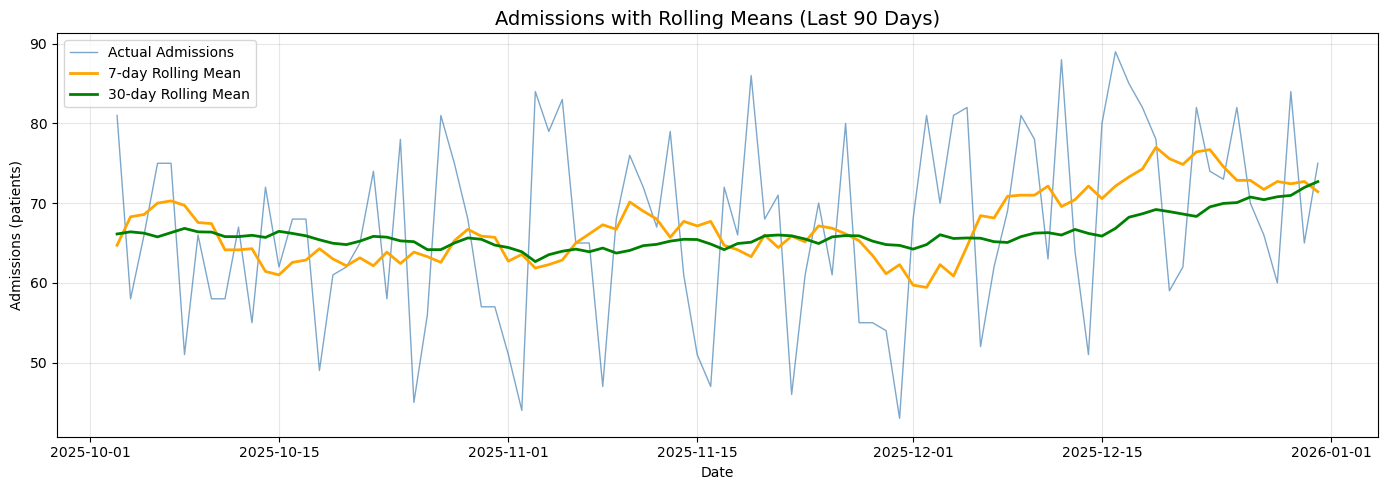

In [8]:
# Visualize rolling mean vs actual admissions
fig, ax = plt.subplots(figsize=(14, 5))

# Plot last 90 days for clarity
plot_data = df_features.tail(90)

ax.plot(plot_data.index, plot_data['admissions'], label='Actual Admissions', 
        color='steelblue', linewidth=1, alpha=0.7)
ax.plot(plot_data.index, plot_data['admissions_roll7_mean'], label='7-day Rolling Mean', 
        color='orange', linewidth=2)
ax.plot(plot_data.index, plot_data['admissions_roll30_mean'], label='30-day Rolling Mean', 
        color='green', linewidth=2)

ax.set_title('Admissions with Rolling Means (Last 90 Days)', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Admissions (patients)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 4. Expanding Window Features

**Expanding window** features use ALL past data up to that point, unlike rolling windows that use a fixed window size.

```
Day 1: 100  →  Expanding Mean: 100
Day 2: 120  →  Expanding Mean: 110   (100+120)/2
Day 3: 115  →  Expanding Mean: 111.7 (100+120+115)/3
Day 4: 130  →  Expanding Mean: 116.3 (100+120+115+130)/4
```

In [9]:
# Expanding window statistics
df_features['admissions_expanding_mean'] = df_features['admissions'].shift(1).expanding().mean()
df_features['admissions_expanding_std'] = df_features['admissions'].shift(1).expanding().std()
df_features['admissions_expanding_max'] = df_features['admissions'].shift(1).expanding().max()

print("Expanding window features created!")
df_features[['admissions', 'admissions_expanding_mean', 'admissions_expanding_max']].tail(10)

Expanding window features created!


,admissions,admissions_expanding_mean,admissions_expanding_max
date,,,
2025-12-22,82,67.426335,100.0
2025-12-23,74,67.439742,100.0
2025-12-24,73,67.445772,100.0
2025-12-25,82,67.450872,100.0
2025-12-26,70,67.464220,100.0
2025-12-27,66,67.466544,100.0
2025-12-28,60,67.465201,100.0
2025-12-29,84,67.458371,100.0
2025-12-30,65,67.473492,100.0


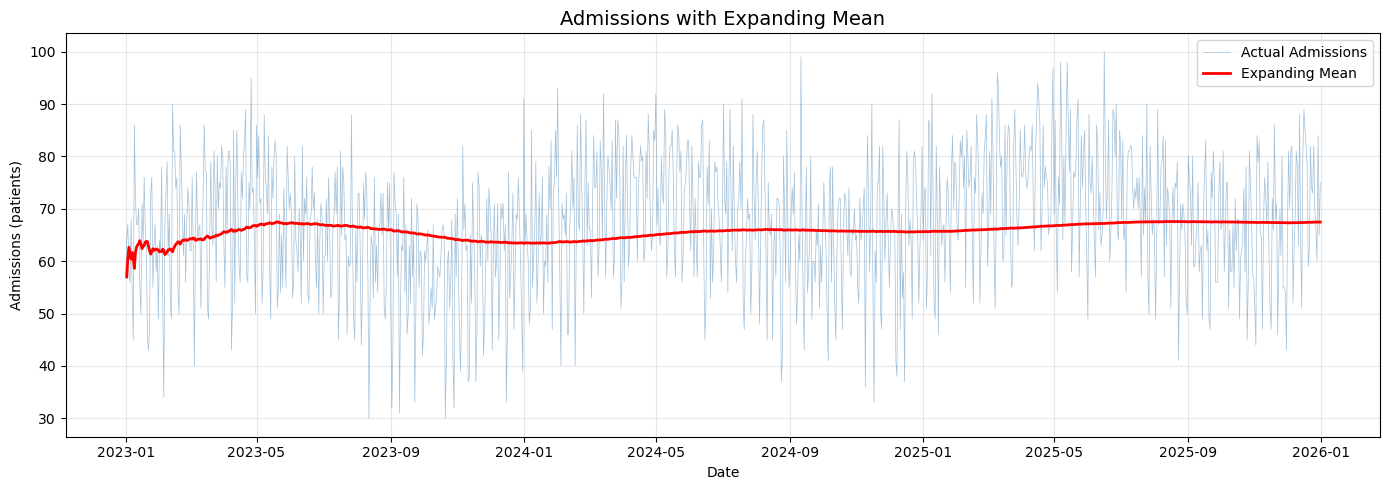

In [10]:
# Visualize expanding mean
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_features.index, df_features['admissions'], label='Actual Admissions', 
        color='steelblue', linewidth=0.5, alpha=0.5)
ax.plot(df_features.index, df_features['admissions_expanding_mean'], label='Expanding Mean', 
        color='red', linewidth=2)

ax.set_title('Admissions with Expanding Mean', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Admissions (patients)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 5. Seasonal/Cyclical Features

**Seasonal features** capture recurring patterns in time series data.

| Feature | Captures |
| :--- | :--- |
| Day of Week | Weekly patterns (weekday vs weekend) |
| Month | Monthly patterns |
| Quarter | Quarterly business cycles |
| Day of Year | Yearly patterns |
| Hour | Daily patterns (for hourly data) |

In [11]:
# Extract seasonal features from datetime index
df_features['day_of_week'] = df_features.index.dayofweek      # 0=Monday, 6=Sunday
df_features['day_of_month'] = df_features.index.day
df_features['day_of_year'] = df_features.index.dayofyear
df_features['week_of_year'] = df_features.index.isocalendar().week.astype(int)
df_features['month'] = df_features.index.month
df_features['quarter'] = df_features.index.quarter
df_features['year'] = df_features.index.year

# Binary features
df_features['is_weekend'] = (df_features['day_of_week'] >= 5).astype(int)
df_features['is_month_start'] = df_features.index.is_month_start.astype(int)
df_features['is_month_end'] = df_features.index.is_month_end.astype(int)

print("Seasonal features created!")
df_features[['admissions', 'day_of_week', 'month', 'quarter', 'is_weekend']].head(10)

Seasonal features created!


,admissions,day_of_week,month,quarter,is_weekend
date,,,,,
2023-01-01,57,6,1,1,1
2023-01-02,64,0,1,1,0
2023-01-03,67,1,1,1,0
2023-01-04,58,2,1,1,0
2023-01-05,56,3,1,1,0
2023-01-06,68,4,1,1,0
2023-01-07,54,5,1,1,1
2023-01-08,45,6,1,1,1
2023-01-09,86,0,1,1,0


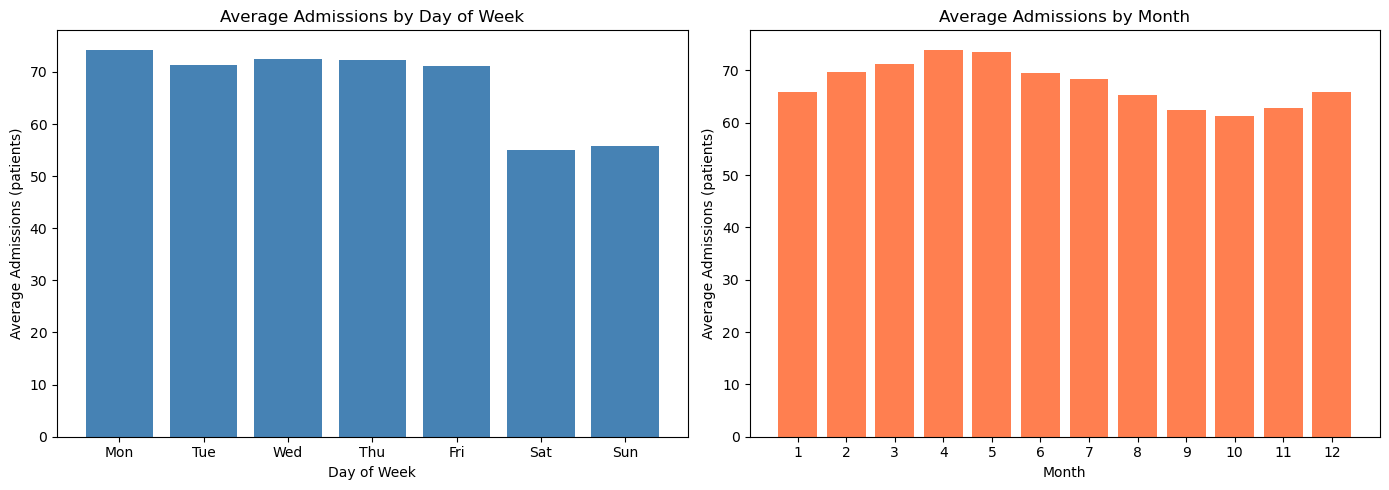

In [12]:
# Visualize admissions by day of week
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Day of week pattern
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow_admissions = df_features.groupby('day_of_week')['admissions'].mean()
axes[0].bar(day_names, dow_admissions.values, color='steelblue')
axes[0].set_title('Average Admissions by Day of Week', fontsize=12)
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Average Admissions (patients)')

# Monthly pattern
month_admissions = df_features.groupby('month')['admissions'].mean()
axes[1].bar(range(1, 13), month_admissions.values, color='coral')
axes[1].set_title('Average Admissions by Month', fontsize=12)
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Admissions (patients)')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

### Cyclical Encoding with Sine/Cosine

For cyclical features like day of week or month, linear encoding (0-6 or 1-12) doesn't capture that Sunday (6) is close to Monday (0). **Sine/Cosine encoding** preserves this cyclical relationship.

In [13]:
# Cyclical encoding for day of week (7-day cycle)
df_features['dow_sin'] = np.sin(2 * np.pi * df_features['day_of_week'] / 7)
df_features['dow_cos'] = np.cos(2 * np.pi * df_features['day_of_week'] / 7)

# Cyclical encoding for month (12-month cycle)
df_features['month_sin'] = np.sin(2 * np.pi * df_features['month'] / 12)
df_features['month_cos'] = np.cos(2 * np.pi * df_features['month'] / 12)

# Cyclical encoding for day of year (365-day cycle)
df_features['doy_sin'] = np.sin(2 * np.pi * df_features['day_of_year'] / 365)
df_features['doy_cos'] = np.cos(2 * np.pi * df_features['day_of_year'] / 365)

print("Cyclical encoding created!")
df_features[['day_of_week', 'dow_sin', 'dow_cos']].head(10)

Cyclical encoding created!


,day_of_week,dow_sin,dow_cos
date,,,
2023-01-01,6,-0.781831,0.623490
2023-01-02,0,0.000000,1.000000
2023-01-03,1,0.781831,0.623490
2023-01-04,2,0.974928,-0.222521
2023-01-05,3,0.433884,-0.900969
2023-01-06,4,-0.433884,-0.900969
2023-01-07,5,-0.974928,-0.222521
2023-01-08,6,-0.781831,0.623490
2023-01-09,0,0.000000,1.000000


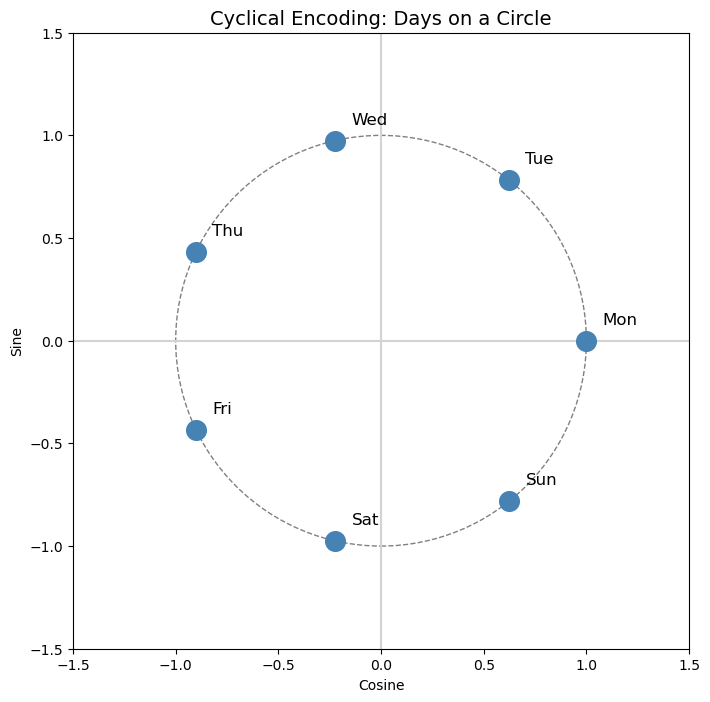

Notice: Sunday (6) is now close to Monday (0) on the circle!


In [14]:
# Visualize cyclical encoding
fig, ax = plt.subplots(figsize=(8, 8))

# Plot day of week as points on a circle
days = df_features[['day_of_week', 'dow_sin', 'dow_cos']].drop_duplicates().sort_values('day_of_week')
day_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

ax.scatter(days['dow_cos'], days['dow_sin'], s=200, c='steelblue', zorder=3)
for i, row in days.iterrows():
    ax.annotate(day_labels[int(row['day_of_week'])], 
                (row['dow_cos'] + 0.08, row['dow_sin'] + 0.08), fontsize=12)

# Draw circle
circle = plt.Circle((0, 0), 1, fill=False, color='gray', linestyle='--')
ax.add_patch(circle)

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect('equal')
ax.axhline(y=0, color='lightgray')
ax.axvline(x=0, color='lightgray')
ax.set_title('Cyclical Encoding: Days on a Circle', fontsize=14)
ax.set_xlabel('Cosine')
ax.set_ylabel('Sine')
plt.show()

print("Notice: Sunday (6) is now close to Monday (0) on the circle!")

---

## 6. Difference Features

**Difference features** measure the change from one period to another. They help remove trends and make the series more stationary.

| Type | Formula | Use Case |
| :--- | :--- | :--- |
| First Difference | value(t) - value(t-1) | Remove linear trend |
| Seasonal Difference | value(t) - value(t-7) | Remove weekly pattern |
| Percent Change | (value(t) - value(t-1)) / value(t-1) | Relative change |

In [15]:
# Difference features
# First difference: change from previous day
df_features['admissions_diff1'] = df_features['admissions'].diff(1)

# Weekly difference: change from same day last week
df_features['admissions_diff7'] = df_features['admissions'].diff(7)

# Percent change from previous day
df_features['admissions_pct_change'] = df_features['admissions'].pct_change(1) * 100

print("Difference features created!")
df_features[['admissions', 'admissions_diff1', 'admissions_diff7', 'admissions_pct_change']].head(10)

Difference features created!


,admissions,admissions_diff1,admissions_diff7,admissions_pct_change
date,,,,
2023-01-01,57,NaN,NaN,NaN
2023-01-02,64,7.0,NaN,12.280702
2023-01-03,67,3.0,NaN,4.687500
2023-01-04,58,-9.0,NaN,-13.432836
2023-01-05,56,-2.0,NaN,-3.448276
2023-01-06,68,12.0,NaN,21.428571
2023-01-07,54,-14.0,NaN,-20.588235
2023-01-08,45,-9.0,-12.0,-16.666667
2023-01-09,86,41.0,22.0,91.111111


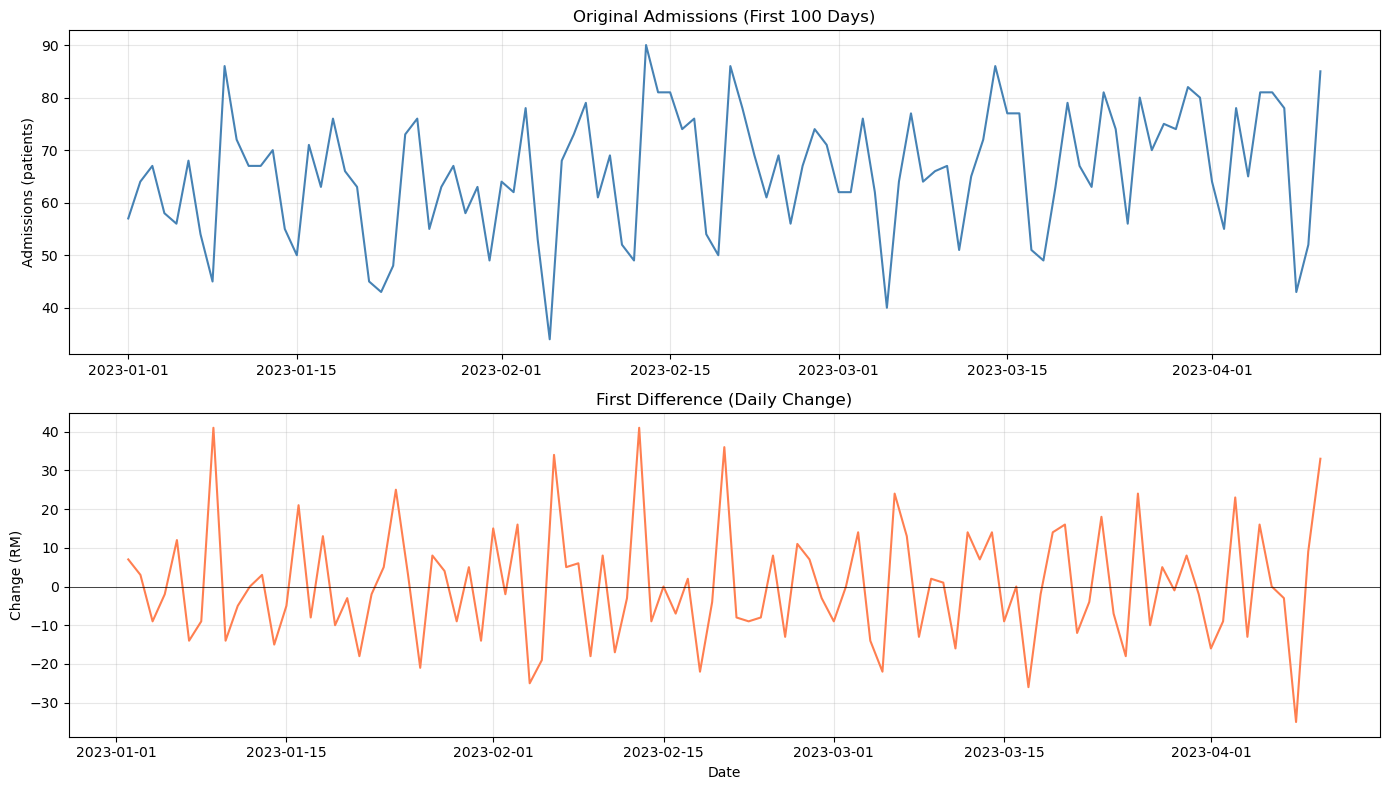

The differenced series removes the trend and shows day-to-day variation.


In [16]:
# Visualize original vs differenced series
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Original series
axes[0].plot(df_features.index[:100], df_features['admissions'][:100], color='steelblue')
axes[0].set_title('Original Admissions (First 100 Days)', fontsize=12)
axes[0].set_ylabel('Admissions (patients)')
axes[0].grid(True, alpha=0.3)

# First difference
axes[1].plot(df_features.index[:100], df_features['admissions_diff1'][:100], color='coral')
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[1].set_title('First Difference (Daily Change)', fontsize=12)
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Change (RM)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("The differenced series removes the trend and shows day-to-day variation.")

---

## 7. TimeSeriesSplit for Cross-Validation

In time series, we **cannot use random train/test splits** because it would leak future information into training. We must respect temporal order.

**TimeSeriesSplit** creates folds where training data always comes before test data.

```
Fold 1: [Train: ████     ] [Test: █]
Fold 2: [Train: █████    ] [Test: █]
Fold 3: [Train: ██████   ] [Test: █]
Fold 4: [Train: ███████  ] [Test: █]
Fold 5: [Train: ████████ ] [Test: █]
```

In [17]:
# Prepare data for modeling (drop rows with NaN from lag features)
feature_cols = ['admissions_lag1', 'admissions_lag7', 'admissions_roll7_mean', 
                'day_of_week', 'month', 'is_weekend']

# Drop NaN and get clean dataset
df_model = df_features.dropna(subset=feature_cols + ['admissions'])

X = df_model[feature_cols]
y = df_model['admissions']

print(f"Features: {feature_cols}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Features: ['admissions_lag1', 'admissions_lag7', 'admissions_roll7_mean', 'day_of_week', 'month', 'is_weekend']
X shape: (1089, 6)
y shape: (1089,)


In [18]:
# Create TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

print("TimeSeriesSplit Folds:")
print("-" * 60)

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), 1):
    train_start = X.index[train_idx[0]].strftime('%Y-%m-%d')
    train_end = X.index[train_idx[-1]].strftime('%Y-%m-%d')
    test_start = X.index[test_idx[0]].strftime('%Y-%m-%d')
    test_end = X.index[test_idx[-1]].strftime('%Y-%m-%d')
    
    print(f"Fold {fold}: Train [{train_start} to {train_end}] ({len(train_idx)} days)")
    print(f"        Test  [{test_start} to {test_end}] ({len(test_idx)} days)")
    print()

TimeSeriesSplit Folds:
------------------------------------------------------------
Fold 1: Train [2023-01-08 to 2023-07-10] (184 days)
        Test  [2023-07-11 to 2024-01-07] (181 days)

Fold 2: Train [2023-01-08 to 2024-01-07] (365 days)
        Test  [2024-01-08 to 2024-07-06] (181 days)

Fold 3: Train [2023-01-08 to 2024-07-06] (546 days)
        Test  [2024-07-07 to 2025-01-03] (181 days)

Fold 4: Train [2023-01-08 to 2025-01-03] (727 days)
        Test  [2025-01-04 to 2025-07-03] (181 days)

Fold 5: Train [2023-01-08 to 2025-07-03] (908 days)
        Test  [2025-07-04 to 2025-12-31] (181 days)



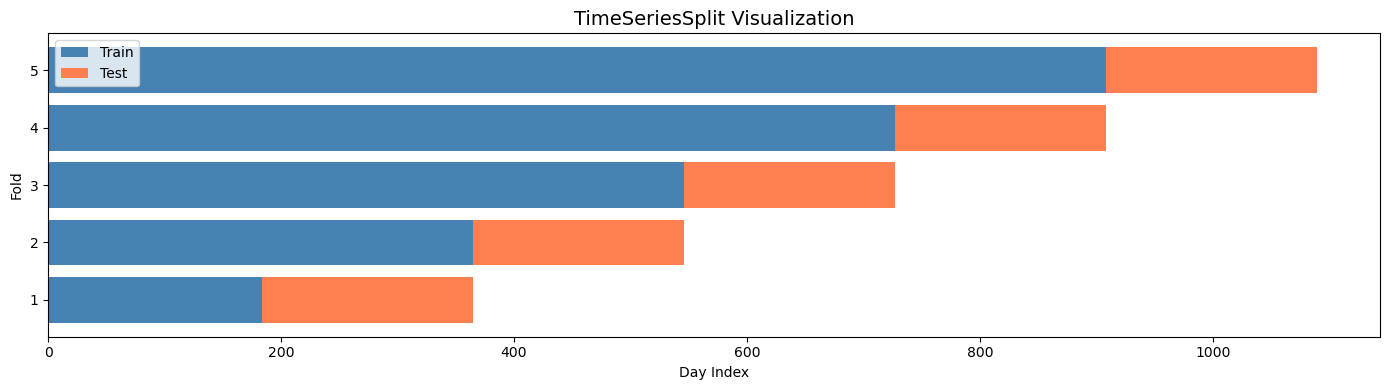

In [19]:
# Visualize TimeSeriesSplit
fig, ax = plt.subplots(figsize=(14, 4))

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), 1):
    # Plot training period
    ax.barh(fold, len(train_idx), left=train_idx[0], color='steelblue', 
            label='Train' if fold == 1 else '')
    # Plot test period
    ax.barh(fold, len(test_idx), left=test_idx[0], color='coral', 
            label='Test' if fold == 1 else '')

ax.set_xlabel('Day Index')
ax.set_ylabel('Fold')
ax.set_title('TimeSeriesSplit Visualization', fontsize=14)
ax.legend(loc='upper left')
ax.set_yticks(range(1, 6))
plt.tight_layout()
plt.show()

In [20]:
# Example: Cross-validation with a simple model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = LinearRegression()
mae_scores = []
rmse_scores = []

print("Cross-Validation Results:")
print("-" * 50)

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    mae_scores.append(mae)
    rmse_scores.append(rmse)
    
    print(f"Fold {fold}: MAE = {mae:.2f}, RMSE = {rmse:.2f}")

print("-" * 50)
print(f"Average MAE: {np.mean(mae_scores):.2f} (+/- {np.std(mae_scores):.2f})")
print(f"Average RMSE: {np.mean(rmse_scores):.2f} (+/- {np.std(rmse_scores):.2f})")

Cross-Validation Results:
--------------------------------------------------
Fold 1: MAE = 7.51, RMSE = 9.27
Fold 2: MAE = 6.77, RMSE = 8.56
Fold 3: MAE = 7.62, RMSE = 9.54
Fold 4: MAE = 7.23, RMSE = 9.00
Fold 5: MAE = 6.85, RMSE = 8.40
--------------------------------------------------
Average MAE: 7.20 (+/- 0.34)
Average RMSE: 8.96 (+/- 0.43)


---

## 8. Summary: All Features Created

Let's review all the time series features we've created:

In [21]:
# List all features by category
feature_categories = {
    'Lag Features': [col for col in df_features.columns if 'lag' in col],
    'Rolling Features': [col for col in df_features.columns if 'roll' in col],
    'Expanding Features': [col for col in df_features.columns if 'expanding' in col],
    'Seasonal Features': ['day_of_week', 'day_of_month', 'day_of_year', 'week_of_year', 
                          'month', 'quarter', 'year', 'is_weekend', 'is_month_start', 'is_month_end'],
    'Cyclical Features': [col for col in df_features.columns if '_sin' in col or '_cos' in col],
    'Difference Features': [col for col in df_features.columns if 'diff' in col or 'pct' in col]
}

print("=" * 60)
print("TIME SERIES FEATURES SUMMARY")
print("=" * 60)

total = 0
for category, features in feature_categories.items():
    print(f"\n{category} ({len(features)})")
    print("-" * 40)
    for feat in features:
        print(f"  • {feat}")
    total += len(features)

print("\n" + "=" * 60)
print(f"Total time series features created: {total}")

TIME SERIES FEATURES SUMMARY

Lag Features (8)
----------------------------------------
  • admissions_lag1
  • admissions_lag7
  • admissions_lag14
  • admissions_lag365
  • admissions_lag2
  • admissions_lag3
  • admissions_lag21
  • admissions_lag28

Rolling Features (5)
----------------------------------------
  • admissions_roll7_mean
  • admissions_roll7_std
  • admissions_roll7_min
  • admissions_roll7_max
  • admissions_roll30_mean

Expanding Features (3)
----------------------------------------
  • admissions_expanding_mean
  • admissions_expanding_std
  • admissions_expanding_max

Seasonal Features (10)
----------------------------------------
  • day_of_week
  • day_of_month
  • day_of_year
  • week_of_year
  • month
  • quarter
  • year
  • is_weekend
  • is_month_start
  • is_month_end

Cyclical Features (6)
----------------------------------------
  • dow_sin
  • dow_cos
  • month_sin
  • month_cos
  • doy_sin
  • doy_cos

Difference Features (3)
-------------------------

---

## Exercises

### Exercise 1: Create Additional Lag Features
Create lag features for 30 days (1 month) and 90 days (3 months) ago.

In [22]:
# Your code here
# df_features['admissions_lag30'] = ...
# df_features['admissions_lag90'] = ...

### Exercise 2: Create Rolling Median
Create a 14-day rolling median feature. Why might median be better than mean for some data?

In [23]:
# Your code here
# df_features['admissions_roll14_median'] = ...

### Exercise 3: Holiday Features
Create a feature `is_friday` that is 1 if the day is Friday (day_of_week == 4), 0 otherwise. Also create `is_payday` for the 15th and last day of month.

In [24]:
# Your code here
# df_features['is_friday'] = ...
# df_features['is_payday'] = ...

### Exercise 4: Week-over-Week Change
Create a feature that shows the percentage change compared to the same day last week.

In [25]:
# Your code here
# df_features['wow_pct_change'] = ...

---

## Key Takeaways

1. **Lag features** capture autocorrelation - how past values predict current values
2. **Rolling statistics** smooth noise and capture recent trends
3. **Expanding windows** use all historical data for cumulative features
4. **Seasonal features** capture recurring patterns (daily, weekly, monthly, yearly)
5. **Cyclical encoding** with sin/cos preserves circular relationships
6. **Difference features** remove trends and make series more stationary
7. **Always use TimeSeriesSplit** for cross-validation to avoid data leakage
8. **Shift before rolling** to prevent including current value in features

### Common Pitfalls to Avoid

| Pitfall | Solution |
| :--- | :--- |
| Using future data | Always use `.shift()` to look only at past values |
| Random train/test split | Use `TimeSeriesSplit` for proper validation |
| Too many NaN rows | Balance window size with data availability |
| Ignoring seasonality | Include day, week, month patterns |

---

## Additional Resources

- [Pandas Time Series Documentation](https://pandas.pydata.org/docs/user_guide/timeseries.html)
- [scikit-learn TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)
- [Feature Engineering for Time Series (Kaggle)](https://www.kaggle.com/learn/time-series)

---

*End of Chapter 3b: Time Series Feature Engineering*

---

## How this is used in real work

Demand forecasting, capacity planning, anomaly detection and every churn model with a time axis. The `.shift(1)` before `.rolling()` is the single most-forgotten line in applied ML, and the failure mode is a model that looks excellent in the notebook and is useless in production.

## Where this goes next

**C4** encoding, then **C6** where all of this becomes a pipeline.